In [1]:
import netCDF4 as nc
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import numpy as np
import pickle as pkl
import datetime as dt
import sys
sys.path.append('../../')
from utils import plotting_utils

In [2]:
files =["23_05.nc","23_06.nc","23_07.nc","23_08.nc","23_09.nc","23_10.nc"]#,"23_11.nc","23_12.nc","24_01.nc","24_02.nc","24_03.nc","24_04.nc","24_05.nc"]#["23_08.nc","23_09.nc","23_10.nc","23_11.nc"]
folder = "./Sweden/"

T_files = ["T_23_05.nc","T_23_06.nc","T_23_07.nc","T_23_08.nc","T_23_09.nc","T_23_10.nc"]#,"23_11.nc","23_12.nc","24_01.nc","24_02.nc","24_03.nc","24_04.nc","24_05.nc"]#["23_08.nc","23_09.nc","23_10.nc","23_11.nc"]

time_array_spin = np.array([])
skt_array = np.array([])
t2m_array = np.array([])
tl1_array = np.array([])

sf = np.array([])
smlt = np.array([])
evabs = np.array([])
tp = np.array([])

for file in files:
    ds = nc.Dataset(folder + file,"r")
    ds_T = nc.Dataset(folder + T_files[files.index(file)],"r")
    latitude = ds.variables["latitude"][:]                                              # latitude in degrees north
    longitude = ds.variables["longitude"][:]                                            # longitude in degrees east                    
    time_array_spin= np.append(time_array_spin, np.array(ds.variables["valid_time"][:]))         # time in seconds since 1970-01-01 00:00:00 UTC
    skt_array = np.append(skt_array, np.array(ds_T.variables["skt"][:][:,1,1]))           # skin temperature in K
    t2m_array = np.append(t2m_array, np.array(ds_T.variables["t2m"][:][:,1,1]))      # 2m temperature in K
    tl1_array = np.append(tl1_array, np.array(ds_T.variables["stl1"][:][:,1,1]))      # soil temperature level 1 in K
    sf = np.append(sf, np.array(ds.variables["sf"][:][:,1,1]))
    smlt = np.append(smlt, np.array(ds.variables["smlt"][:][:,1,1]))
    evabs = np.append(evabs, np.array(ds.variables["evabs"][:][:,1,1]))
    tp = np.append(tp, np.array(ds.variables["tp"][:][:,1,1]))

recharge_spin = (tp-sf+evabs+smlt)/60/60                                                 # recharge in m/s   
# recharge_spin = np.convolve(recharge_spin,np.ones(24)/24,mode="same")
dates_spin = [dt.datetime.utcfromtimestamp(t) for t in time_array_spin]

skt_array_spin = (skt_array - 273.15)                                                        # skin temperature in °C
t2m_array_spin = (t2m_array - 273.15)                                                        # 2m temperature in °C
tl1_array_spin = (tl1_array - 273.15)                                                        # soil temperature level 1 in °C

/tmp/ipykernel_159050/724933431.py:32: DeprecationWarning: datetime.datetime.utcfromtimestamp() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.fromtimestamp(timestamp, datetime.UTC).
  dates_spin = [dt.datetime.utcfromtimestamp(t) for t in time_array_spin]


In [3]:
files = ["23_11.nc","23_12.nc","24_01.nc","24_02.nc","24_03.nc","24_04.nc","24_05.nc"]# ["23_12.nc","24_01.nc","24_02.nc","24_03.nc","24_04.nc","24_05.nc"]["23_08.nc","23_09.nc","23_10.nc","23_11.nc"]
folder = "./Sweden/"

T_files = ["T_23_11.nc","T_23_12.nc","T_24_01.nc","T_24_02.nc","T_24_03.nc","T_24_04.nc","T_24_05.nc"]# ["23_12.nc","24_01.nc","24_02.nc","24_03.nc","24_04.nc","24_05.nc"]["23_08.nc","23_09.nc","23_10.nc","23_11.nc"]

time_array_sim = np.array([])
skt_array = np.array([])
t2m_array = np.array([])
tl1_array = np.array([])

sf = np.array([])
smlt = np.array([])
evabs = np.array([])
tp = np.array([])

for file in files:
    ds = nc.Dataset(folder + file,"r")
    ds_T = nc.Dataset(folder + T_files[files.index(file)],"r")
    latitude = ds.variables["latitude"][:]                                              # latitude in degrees north
    longitude = ds.variables["longitude"][:]                                            # longitude in degrees east                    
    time_array_sim = np.append(time_array_sim, np.array(ds.variables["valid_time"][:]))         # time in seconds since 1970-01-01 00:00:00 UTC
    skt_array = np.append(skt_array, np.array(ds_T.variables["skt"][:][:,1,1]))           # skin temperature in K
    t2m_array = np.append(t2m_array, np.array(ds_T.variables["t2m"][:][:,1,1]))      # 2m temperature in K
    tl1_array = np.append(tl1_array, np.array(ds_T.variables["stl1"][:][:,1,1]))      # soil temperature level 1 in K
    sf = np.append(sf, np.array(ds.variables["sf"][:][:,1,1]))
    smlt = np.append(smlt, np.array(ds.variables["smlt"][:][:,1,1]))
    evabs = np.append(evabs, np.array(ds.variables["evabs"][:][:,1,1]))
    tp = np.append(tp, np.array(ds.variables["tp"][:][:,1,1]))

recharge_sim = (tp-sf+evabs+smlt)/60/60                                                   # recharge in m/s   
# recharge_sim = np.convolve(recharge_sim,np.ones(24)/24,mode="same")
dates_sim = [dt.datetime.utcfromtimestamp(t) for t in time_array_sim]
dates = [dates_spin,dates_sim]
print(dates)

skt_array_sim = (skt_array - 273.15)                                                        # skin temperature in °C
t2m_array_sim = (t2m_array - 273.15)                                                        # 2m temperature in °C
tl1_array_sim = (tl1_array - 273.15)                                                        # soil temperature

[[datetime.datetime(2023, 5, 1, 0, 0), datetime.datetime(2023, 5, 1, 1, 0), datetime.datetime(2023, 5, 1, 2, 0), datetime.datetime(2023, 5, 1, 3, 0), datetime.datetime(2023, 5, 1, 4, 0), datetime.datetime(2023, 5, 1, 5, 0), datetime.datetime(2023, 5, 1, 6, 0), datetime.datetime(2023, 5, 1, 7, 0), datetime.datetime(2023, 5, 1, 8, 0), datetime.datetime(2023, 5, 1, 9, 0), datetime.datetime(2023, 5, 1, 10, 0), datetime.datetime(2023, 5, 1, 11, 0), datetime.datetime(2023, 5, 1, 12, 0), datetime.datetime(2023, 5, 1, 13, 0), datetime.datetime(2023, 5, 1, 14, 0), datetime.datetime(2023, 5, 1, 15, 0), datetime.datetime(2023, 5, 1, 16, 0), datetime.datetime(2023, 5, 1, 17, 0), datetime.datetime(2023, 5, 1, 18, 0), datetime.datetime(2023, 5, 1, 19, 0), datetime.datetime(2023, 5, 1, 20, 0), datetime.datetime(2023, 5, 1, 21, 0), datetime.datetime(2023, 5, 1, 22, 0), datetime.datetime(2023, 5, 1, 23, 0), datetime.datetime(2023, 5, 2, 0, 0), datetime.datetime(2023, 5, 2, 1, 0), datetime.datetime(2023

/tmp/ipykernel_159050/3956498960.py:32: DeprecationWarning: datetime.datetime.utcfromtimestamp() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.fromtimestamp(timestamp, datetime.UTC).
  dates_sim = [dt.datetime.utcfromtimestamp(t) for t in time_array_sim]


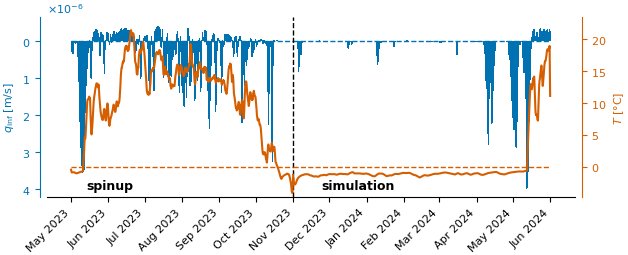

In [4]:
fig, (ax, ax_cp) = plotting_utils.plot_forcing_data(
    time_array_spin, time_array_sim,
    tl1_array_spin, tl1_array_sim,
    recharge_spin, recharge_sim,
)

In [5]:
time = (time_array_sim - time_array_sim[0])                                               # time in seconds since first timestamp         
db = {
    "dates": dates_sim,
    "time": time,
    "skt": skt_array_sim,
    "t2m": t2m_array_sim,
    "tl1": tl1_array_sim,
    "recharge": recharge_sim
}
with open(folder+"sim_2312_2405.pkl", "wb") as f:
        pkl.dump(db, f)

time = (time_array_spin - time_array_spin[0])                                               # time in seconds since first timestamp         
db = {
    "dates": dates_spin,
    "time": time,
    "skt": skt_array_spin,
    "t2m": t2m_array_spin,
    "tl1": tl1_array_spin,
    "recharge": recharge_spin
}
with open(folder+"spinup_2308_2311.pkl", "wb") as f:
        pkl.dump(db, f)